# Data Analysis: Anime


We've been tasked with analyzing the public dataset from **MyAnimeList (MAL)**, a platform where users rate anime and organize them into lists—"Plan to Watch," "Watching," "On Hold," "Dropped," or "Completed"—with date tracking for each entry. Beyond ratings, MAL lets users favorite characters, follow anime news, and join topic-specific clubs (essentially themed group chats for fans).

This dataset captures the entire anime ecosystem: what people watch, how they engage, and what they love.

This dataset is organized into four macro categories that together describe the anime ecosystem from content to audience. The Anime category covers the titles themselves and how people interact with them. The `details` table holds core per-title metadata such as titles, formats, genres, airing dates, and platforms. The `stats` table captures aggregate engagement, including how many users are watching, completed, or dropped each title, along with score distributions. The `ratings` table contains individual user logs that record per-user watch status and numeric ratings. The `recommendations` table links titles with "if you liked X, try Y" relationships that help surface similar shows.

The Characters category represents the cast and how they appear across shows. The `characters` table provides biographies, including identity, background, and notable traits. The `character_anime_works` table maps each character to the anime in which they appear and indicates whether their role is main or supporting. The `character_nicknames` table lists alternate names and fan-used monikers, reflecting how communities refer to characters in practice.

The Creators category documents the people who make anime happen and their credited work. The `person_details` table profiles industry professionals such as voice actors, directors, and animators. The `person_anime_works` table records production credits, specifying who worked on which anime and in what capacity. The `person_voice_works` table focuses on voice acting, showing who voiced which characters and in which language. The `person_alternate_names` table captures stage names and alternative spellings used by creators.

The Users category describes the audience, their habits, and their preferences. The `profiles` table summarizes user demographics and viewing behavior, including how much they have watched, completed, dropped, placed on hold, or plan to watch. The `favs` table highlights user favorites, identifying the anime and characters individual users love most. Taken together, these four categories offer a coherent map of the dataset: titles and engagement live under Anime; personality and presence live under Characters; production roles and credits live under Creators; and audience behavior and preferences live under Users.


## The Anime Phenomenon

This dataset represents one of the most extensive collections of anime industry data:  
aggregating **330k users** across **30k titles** spanning **20+ countries** with more than **10 languages** being used and **450k+ staff and productions** credits across key roles.  
The dataset provides unprecedented insight into the global anime ecosystem, from production to consumption leading us to rich explorations:

**About the Industry:**

- What makes an anime successful?
- Do certain voice actors or studios consistently produce hits?
- How do genres trend over time?

**About Content:**

- Which characters resonate most with audiences?
- What types of anime get recommended together?
- Are there distinct anime "communities" or clusters?

**About Fans:**

- What predicts whether someone will complete or drop an anime?
- How do viewing patterns differ across user demographics?
- Can we build a recommendation system that understands taste?

But why so?

To answer a simple, yet not easy, question:  
**if I want to produce a top tier anime, what should I take care of?**

---


In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))
import utils.graphs_utils as gu

---


Let's start from the big picture. Before diving into what makes a successful anime, we want to understand where the audience is. How did anime spread across the world? Which countries embraced it first, and which are still catching up?


## Global Distribution of Anime Users Over Time

### Interactive Choropleth Map with Plotly

This animated map shows how anime users have joined from different countries over time, **year by year** from 2004 to 2025.


### Understanding the Logarithmic Color Scale

To better visualize countries with varying user populations, we use a **logarithmic scale** for the color gradient. This transformation makes it easier to distinguish between countries with lower user counts while still showing the dominance of major markets.

**Why logarithmic?**

- **Without log scale**: Countries with 50,000+ users dominate the entire color range, making countries with 10-1,000 users appear nearly identical.
- **With log scale**: Each order of magnitude (10 → 100 → 1,000 → 10,000) gets equal visual weight, revealing growth patterns in emerging markets.

**What you'll see:**

- Countries are colored by **log₁₀(Total Users + 1)**
- Hover over any country to see the **actual user count** (not logarithmic)
- The color scale ranges from **Turbo** (high contrast) for better differentiation

This approach highlights both the anime superpowers (USA, Japan, etc.) and emerging communities worldwide.


In [2]:
# Create the animated map figure and display it
fig = gu.create_animated_map()
fig.show()

Dati aggregati:
Paesi unici prima della normalizzazione: 22
Paesi unici dopo la normalizzazione: 16

Numero totale di record: 324
Anni disponibili: [np.int32(2004), np.int32(2005), np.int32(2006), np.int32(2007), np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


**What the map reveals:**

1. **The U.S. dominates, but not alone** - North America leads Western markets, with the United States showing the highest user density outside Asia. Canada follows closely. English accessibility and cultural openness to Japanese content clearly matter.

2. **Europe's split personality** - France, Germany, and the UK show strong engagement, while Eastern Europe lags behind. Western Europe's early access to localized content and convention culture gave them a head start.

3. **Latin America's explosive rise** - Brazil, Mexico, and Argentina light up in recent years. Spanish and Portuguese-speaking markets are growing fast—yet they remain largely untapped by producers.

4. **Asia-Pacific: the home advantage** - Japan's deep color is expected (though many locals use domestic platforms). What's striking: South Korea, Thailand, and the Philippines show intense engagement. Cultural proximity drives adoption.

5. **The forgotten continents** - Middle East and Africa remain nearly invisible. Limited platform access, language barriers, or cultural/regulatory constraints keep these massive markets locked out.

6. **2010: the streaming revolution** - User counts exploded after 2010. Crunchyroll, Netflix, and legal streaming platforms democratized access globally. Before 2010? Growth was modest and concentrated in traditional markets.

**What this means for producers:**

- **Global reach requires global strategy** - Success isn't just about quality content—it's about accessibility, localization, and understanding regional preferences
- **Timing matters** - The data shows clear windows when markets open up; early movers in emerging regions could capture loyal audiences
- **Don't ignore the "small" markets** - Today's niche could be tomorrow's Brazil or Philippines—exponential growth happens fast once infrastructure arrives
- **Streaming changed everything** - The 2010+ surge isn't coincidence—it's infrastructure
- **Massive untapped potential** - Africa and the Middle East represent the next frontier if barriers fall
- **Culture matters more than distance** - Geographic proximity to Japan predicts engagement better than GDP


This raises an interesting question: does the popularity of anime dubbed/subbed in specific languages actually match the geographic distribution we just saw? If localization truly drives adoption, we should see a clear correlation between language availability and user engagement in those regions.


In [3]:
# Display language distribution to validate localization hypothesis
fig = gu.language_vs_geographic_distribution()
fig.show()

**Key observations:**

The language distribution largely mirrors the geographic patterns we saw earlier—English dominates, followed by Spanish and Portuguese (Latin America's rise), and French/German (Western Europe's strength). But here's what's interesting:

- **English's dominance isn't just about native speakers** - Many non-English-speaking countries (Philippines, Scandinavia) show high anime engagement precisely because English subs/dubs are widely accessible
- **The Spanish opportunity is real** - Latin America's explosive growth correlates perfectly with increased Spanish localization efforts by streaming platforms
- **Language barriers still matter** - Regions with less common languages (Middle East, Africa) remain underserved, confirming our earlier geographic observations

This validates our hypothesis: **localization drives adoption**. If you want to crack a new market, you need to speak their language—literally.


## The Voice Behind the Character

If language drives adoption this strongly, what about the voice actors themselves? Do certain VAs consistently voice beloved characters, or is popularity purely about the character and story? Let's explore whether talent matters as much as localization.


**Reading the visualization:**

This reveals whether top VAs got there by voicing many characters, or by consistently landing iconic roles.

- **Bar length** = Total favorites across all characters voiced by that VA

- **Bar color** = Average favorites per character (darker = higher average)

- **Text inside bars** = Number of characters voiced


In [4]:
# Analyze voice actor impact on character popularity
fig = gu.voice_actor_character_popularity(top_n=20)
fig.show()

**What the data reveals:**

There isn't really a clear pattern. Some VAs reach the top by voicing dozens of characters (volume strategy), while others get there with just a handful of iconic roles (quality strategy). The color variation shows that high average favorites don't guarantee a top position—you need either consistency across many roles or a few breakout performances.

**Does the voice actor matter?**

Not as much as you might think. Unlike localization—which shows a direct, strong correlation with adoption—voice actors don't seem to be a major driver of character or anime popularity. Sure, certain legendary VAs (like those at the top of this chart) have devoted fanbases, but they're the exception, not the rule.

This makes sense if you think about it: most viewers don't choose an anime based on who voices the characters. They choose based on story, genre, art style, and recommendations. The VA's performance enhances the experience, but it rarely _makes_ or _breaks_ a show's success.

**Takeaway for producers:** Voice acting quality matters for execution, but it won't save a weak story or create buzz on its own. Invest in good VAs, but don't expect them to carry your marketing.


---


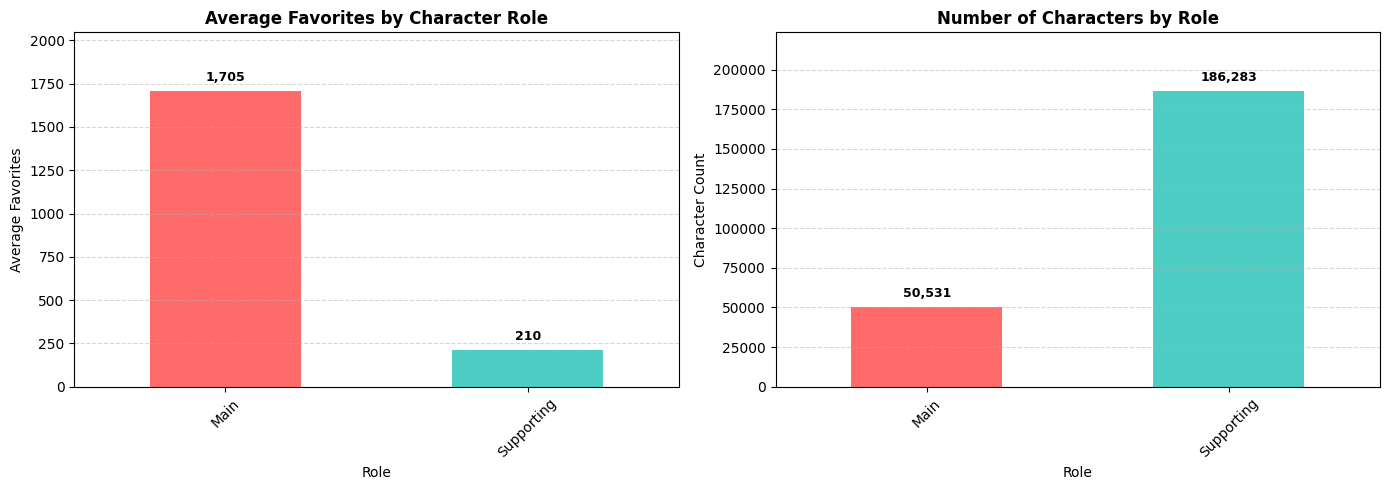

In [5]:
fig, ax = gu.character_popularity_by_role()

In [6]:
fig = gu.character_popularity_by_genre_bars()
fig.show()

In [9]:
fig = gu.recommendation_genre_cooccurrence()
fig.show()

In [2]:
fig = gu.recommendation_type_patterns()
fig.show()